# Notebook 07 — XAI: GradientSHAP Attribution

**Method:** GradientSHAP — game-theoretic gradient attribution  
**Applied to:** LSTM, 1D-CNN, and Transformer  
**Dataset:** NASA CMAPSS — FD001


## 0 · Imports and setup

In [2]:
import sys
from pathlib import Path
PROJECT_ROOT = Path('..').resolve()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import numpy as np
import torch
import matplotlib.pyplot as plt
import seaborn as sns

from src.utils.config import DATA_PROC, OUT_MODELS, OUT_FIGURES
from src.models.lstm        import LSTMModel
from src.models.cnn1d       import CNN1DModel
from src.models.transformer import TransformerModel
from src.explainability.gradientshap import GradientSHAPExplainer

sns.set_theme(style='whitegrid', font_scale=1.1)
plt.rcParams.update({'figure.dpi': 120, 'figure.facecolor': 'white'})

SUBSET  = 'FD001'
DEVICE  = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
SENSORS = ['s_2','s_3','s_4','s_7','s_8','s_9','s_11',
           's_12','s_13','s_14','s_15','s_17','s_20','s_21']
print(f'Device: {DEVICE}')

Device: cpu


## 1 · Load test data and trained models

In [4]:
proc   = DATA_PROC / SUBSET
X_test = np.load(proc / 'X_test.npy')   # (100, 30, 14)
y_test = np.load(proc / 'y_test.npy')   # (100,)

print(f'Test windows : {X_test.shape}')
print(f'RUL range    : [{y_test.min():.0f}, {y_test.max():.0f}] cycles')
print(f'Test engines : {len(X_test)}')

def load_model(cls, name, subset=SUBSET):
    m = cls()
    ckpt = OUT_MODELS / f'{name}_{subset}_best.pt'
    m.load_state_dict(torch.load(ckpt, map_location=DEVICE, weights_only=True))
    m.eval()
    return m.to(DEVICE)

lstm_model  = load_model(LSTMModel,       'lstm')
cnn_model   = load_model(CNN1DModel,      'cnn1d')
trans_model = load_model(TransformerModel,'transformer')
print('\nAll models loaded ')

Test windows : (100, 30, 14)
RUL range    : [7, 125] cycles
Test engines : 100

All models loaded 


## 2 · Select representative engines

In [5]:
# Pick 3 engines: healthy (high RUL), mid-life, near-failure (low RUL)
target_ruls  = [110, 60, 15]
engine_ids   = [int(np.argmin(np.abs(y_test - t))) for t in target_ruls]
actual_ruls  = [y_test[i] for i in engine_ids]
engine_labels = ['Healthy', 'Mid-life', 'Near-failure']

print('Selected engines:')
for label, eid, rul in zip(engine_labels, engine_ids, actual_ruls):
    print(f'  {label:<15} engine_idx={eid:>3}  actual RUL={rul:.0f} cycles')

Selected engines:
  Healthy         engine_idx=  8  actual RUL=111 cycles
  Mid-life        engine_idx= 42  actual RUL=59 cycles
  Near-failure    engine_idx= 55  actual RUL=15 cycles


## 3 · GradientSHAP attributions — LSTM


Saved → C:\Users\rumma\OneDrive\Desktop\Dissertation\xpdm_starter\outputs\figures\shap_lstm_FD001_healthy.png


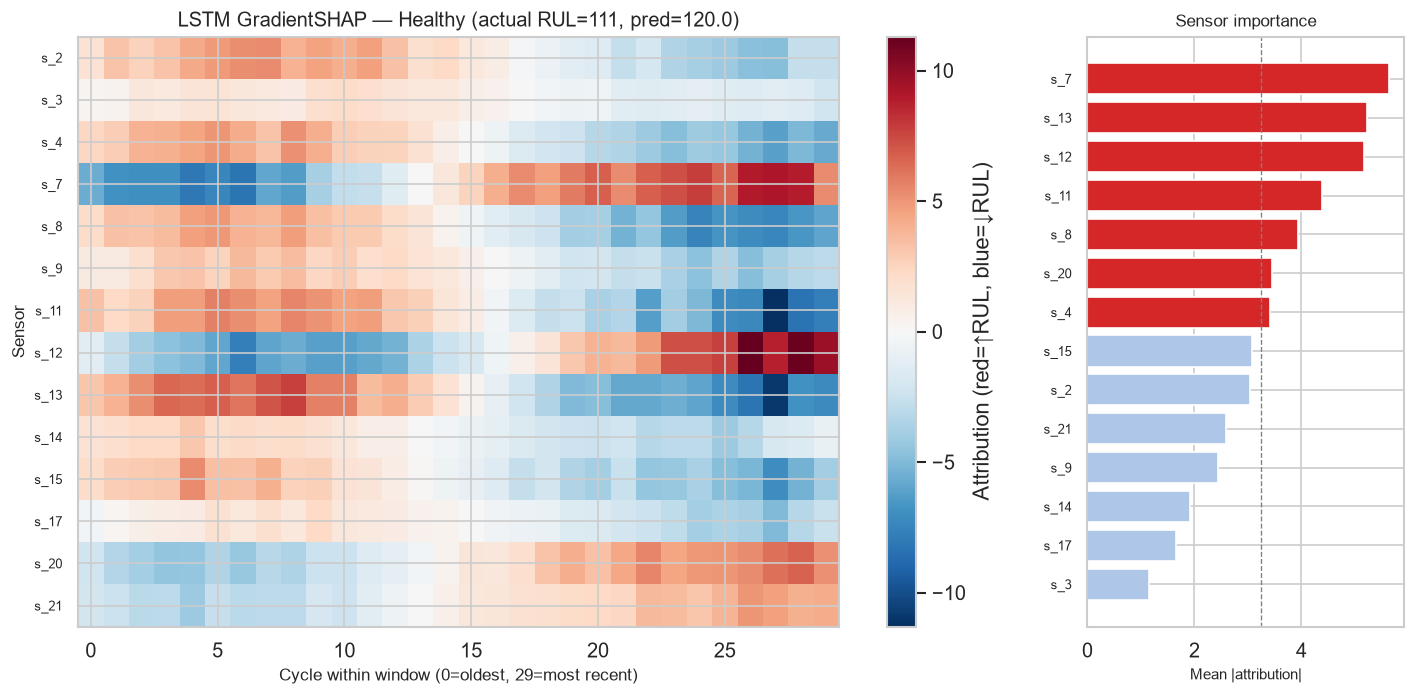

Healthy: top 3 sensors by attribution
  1. s_7     mean attr=5.6435
  2. s_13    mean attr=5.2158
  3. s_12    mean attr=5.1715

Saved → C:\Users\rumma\OneDrive\Desktop\Dissertation\xpdm_starter\outputs\figures\shap_lstm_FD001_mid_life.png


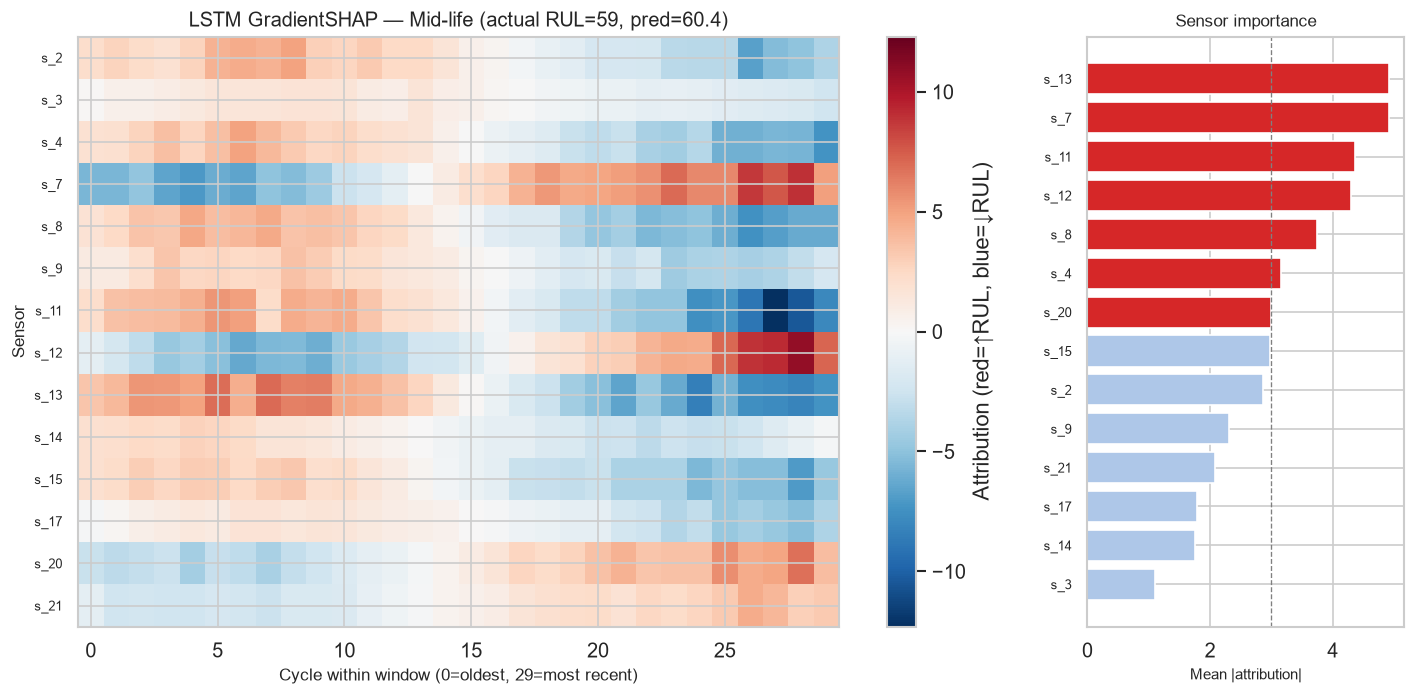

Mid-life: top 3 sensors by attribution
  1. s_13    mean attr=4.9230
  2. s_7     mean attr=4.9129
  3. s_11    mean attr=4.3704

Saved → C:\Users\rumma\OneDrive\Desktop\Dissertation\xpdm_starter\outputs\figures\shap_lstm_FD001_near_failure.png


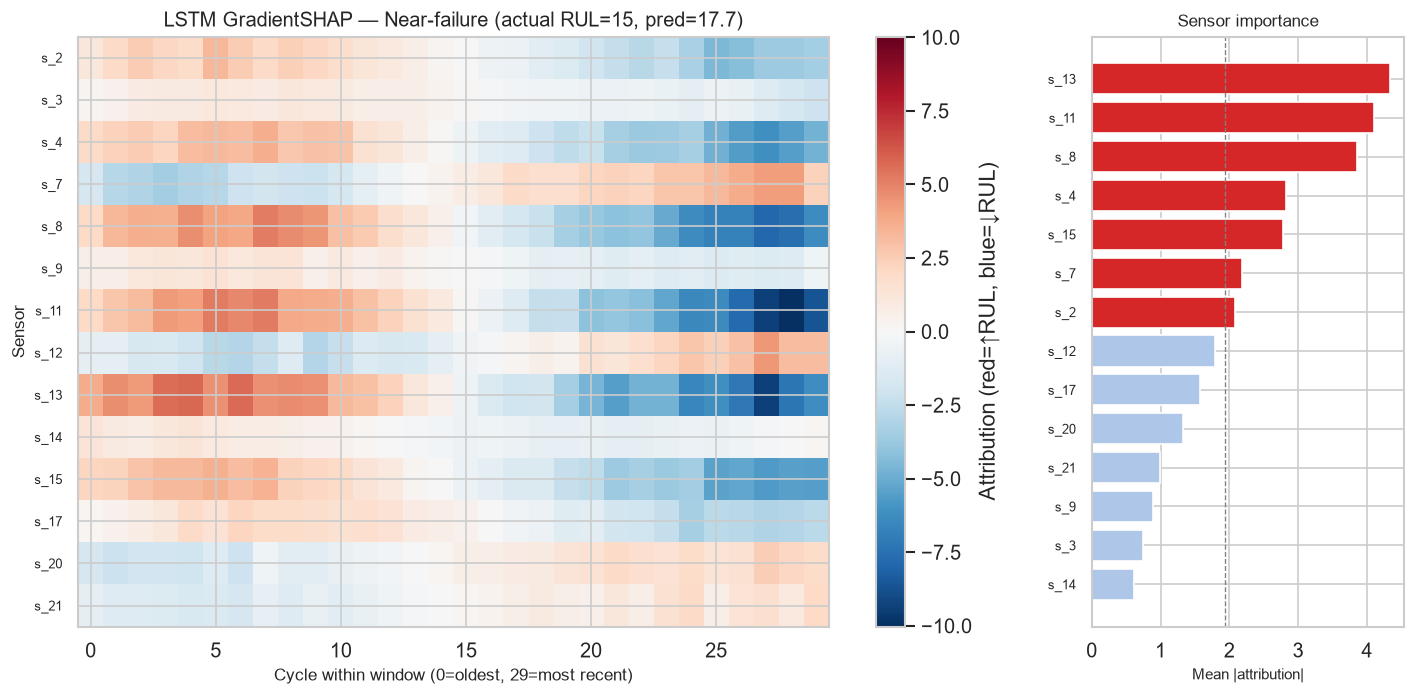

Near-failure: top 3 sensors by attribution
  1. s_13    mean attr=4.3300
  2. s_11    mean attr=4.1089
  3. s_8     mean attr=3.8612



In [13]:
lstm_explainer = GradientSHAPExplainer(lstm_model, DEVICE, n_samples=50)

for label, eid, rul in zip(engine_labels, engine_ids, actual_ruls):
    window = torch.tensor(X_test[eid:eid+1], dtype=torch.float32)

    with torch.no_grad():
        pred = lstm_model(window.to(DEVICE)).item()

    attr = lstm_explainer.attribute(window)

    lstm_explainer.plot(
        attr,
        sensor_names = SENSORS,
        title  = f'LSTM GradientSHAP — {label} (actual RUL={rul:.0f}, pred={pred:.1f})',
        save_path = OUT_FIGURES / f'shap_lstm_{SUBSET}_{label.lower().replace("-","_")}.png',
    )

    print(f'{label}: top 3 sensors by attribution')
    importance = np.abs(attr).mean(axis=0)
    top3 = np.argsort(importance)[::-1][:3]
    for rank, idx in enumerate(top3, 1):
        print(f'  {rank}. {SENSORS[idx]:<6}  mean attr={importance[idx]:.4f}')
    print()

## 4 · GradientSHAP attributions — 1D-CNN

Saved → C:\Users\rumma\OneDrive\Desktop\Dissertation\xpdm_starter\outputs\figures\shap_cnn_FD001_healthy.png


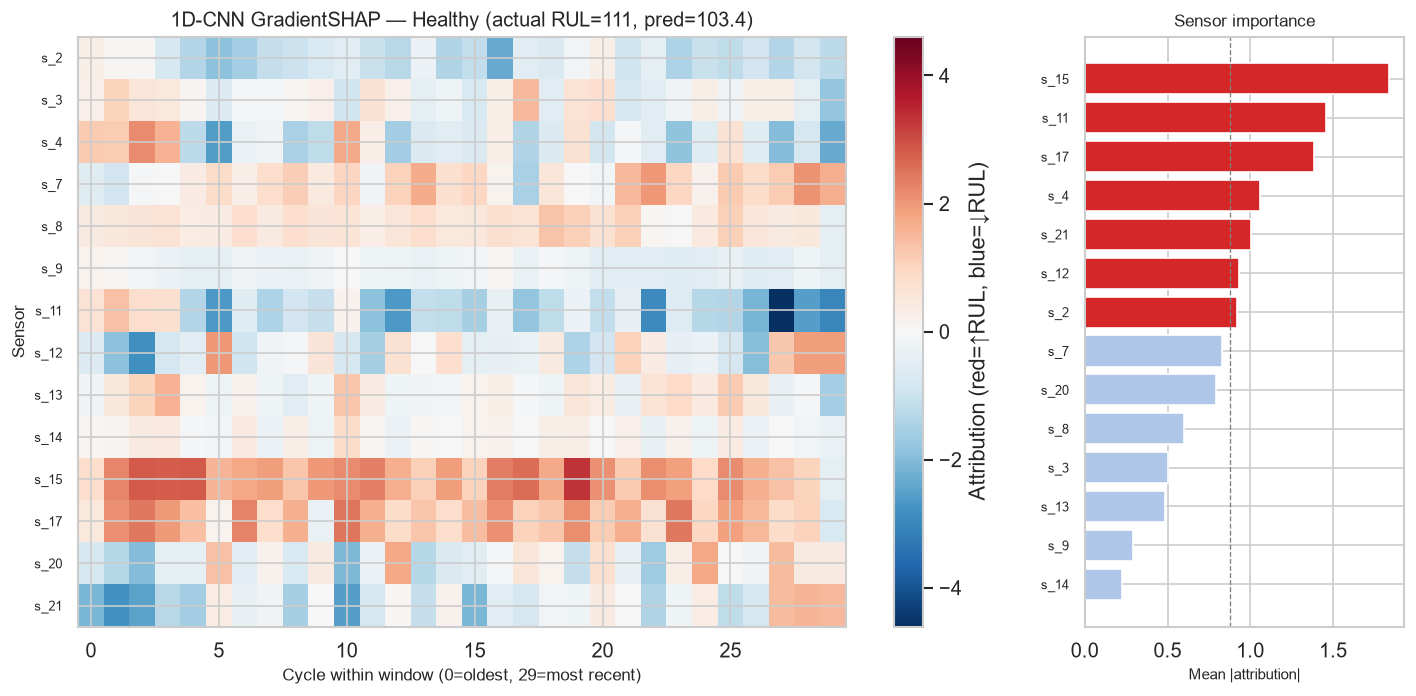

Healthy: top 3 sensors
  1. s_15    mean attr =1.8394
  2. s_11    mean attr =1.4575
  3. s_17    mean attr =1.3850

Saved → C:\Users\rumma\OneDrive\Desktop\Dissertation\xpdm_starter\outputs\figures\shap_cnn_FD001_mid_life.png


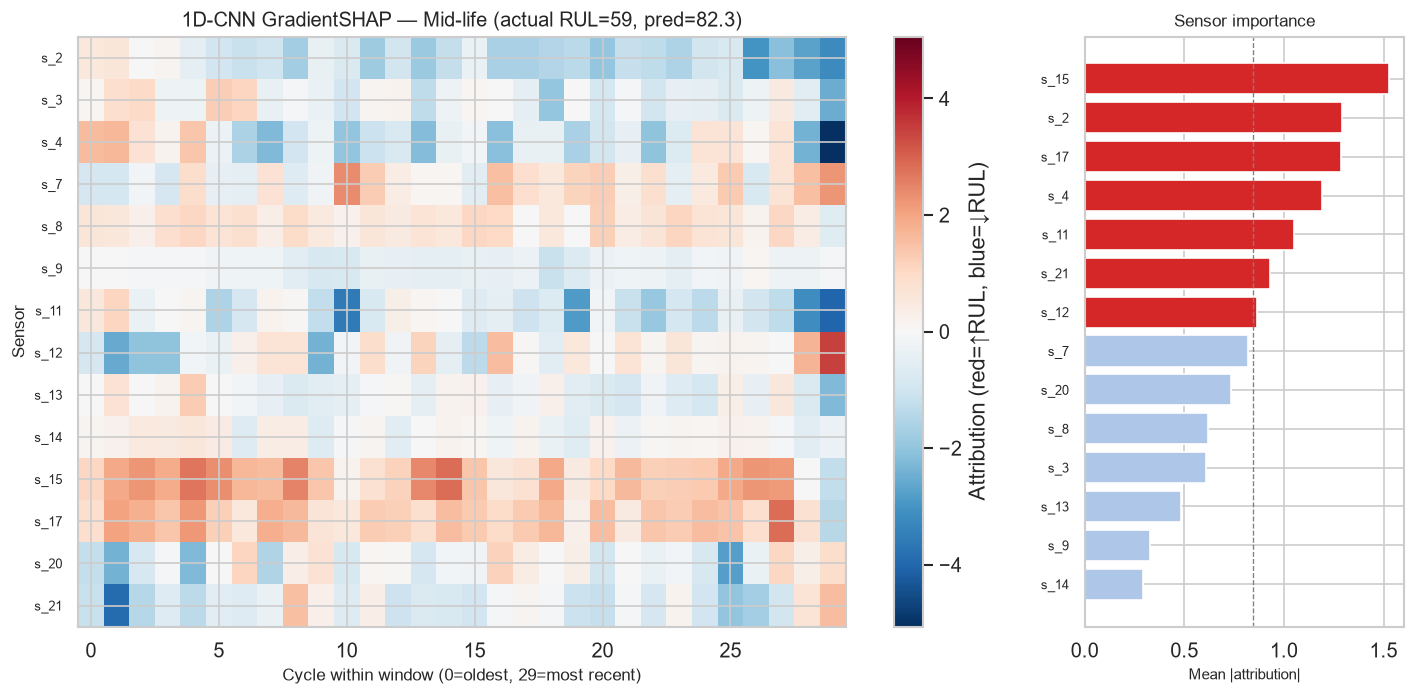

Mid-life: top 3 sensors
  1. s_15    mean attr =1.5289
  2. s_2     mean attr =1.2909
  3. s_17    mean attr =1.2863

Saved → C:\Users\rumma\OneDrive\Desktop\Dissertation\xpdm_starter\outputs\figures\shap_cnn_FD001_near_failure.png


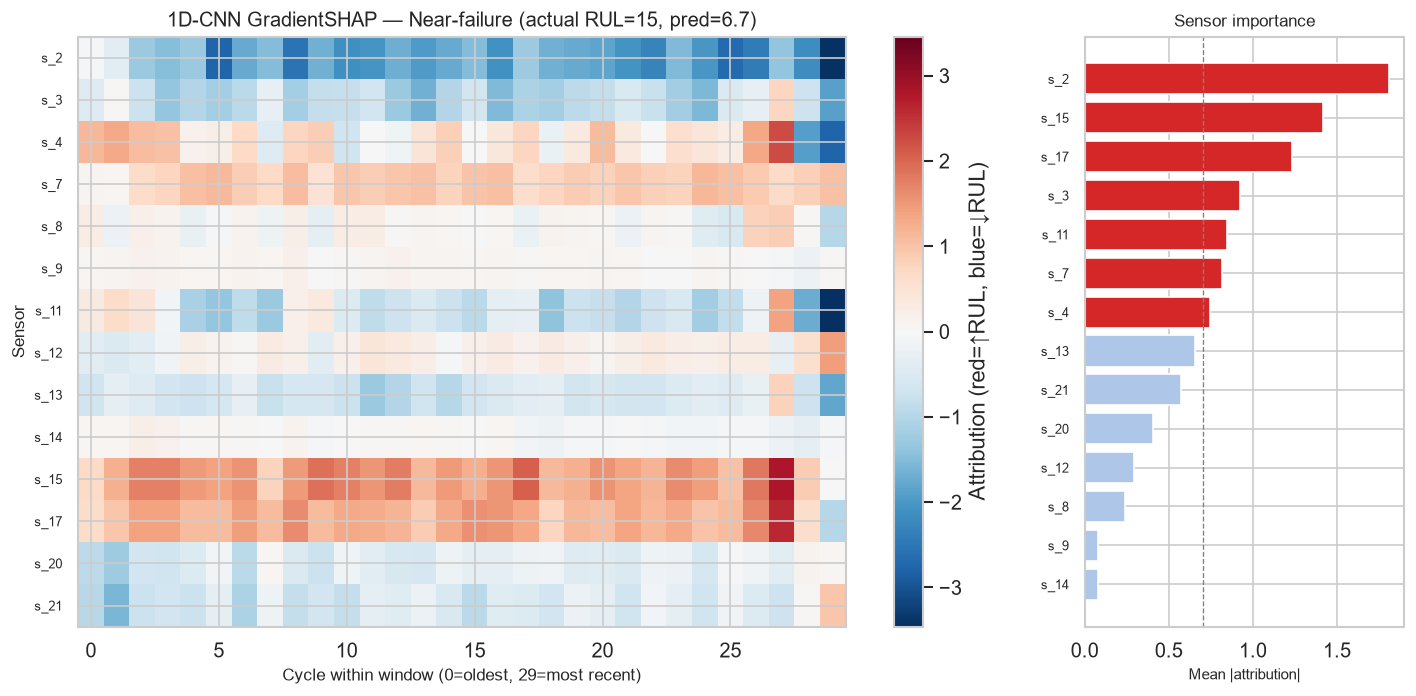

Near-failure: top 3 sensors
  1. s_2     mean attr =1.8104
  2. s_15    mean attr =1.4180
  3. s_17    mean attr =1.2304



In [14]:
cnn_explainer = GradientSHAPExplainer(cnn_model, DEVICE, n_samples=50)

for label, eid, rul in zip(engine_labels, engine_ids, actual_ruls):
    window = torch.tensor(X_test[eid:eid+1], dtype=torch.float32)

    with torch.no_grad():
        pred = cnn_model(window.to(DEVICE)).item()

    attr = cnn_explainer.attribute(window)

    cnn_explainer.plot(
        attr,
        sensor_names = SENSORS,
        title  = f'1D-CNN GradientSHAP — {label} (actual RUL={rul:.0f}, pred={pred:.1f})',
        save_path = OUT_FIGURES / f'shap_cnn_{SUBSET}_{label.lower().replace("-","_")}.png',
    )

    importance = np.abs(attr).mean(axis=0)
    top3 = np.argsort(importance)[::-1][:3]
    print(f'{label}: top 3 sensors')
    for rank, idx in enumerate(top3, 1):
        print(f'  {rank}. {SENSORS[idx]:<6}  mean attr ={importance[idx]:.4f}')
    print()

## 5 · GradientSHAP attributions — Transformer

Saved → C:\Users\rumma\OneDrive\Desktop\Dissertation\xpdm_starter\outputs\figures\shap_transformer_FD001_healthy.png


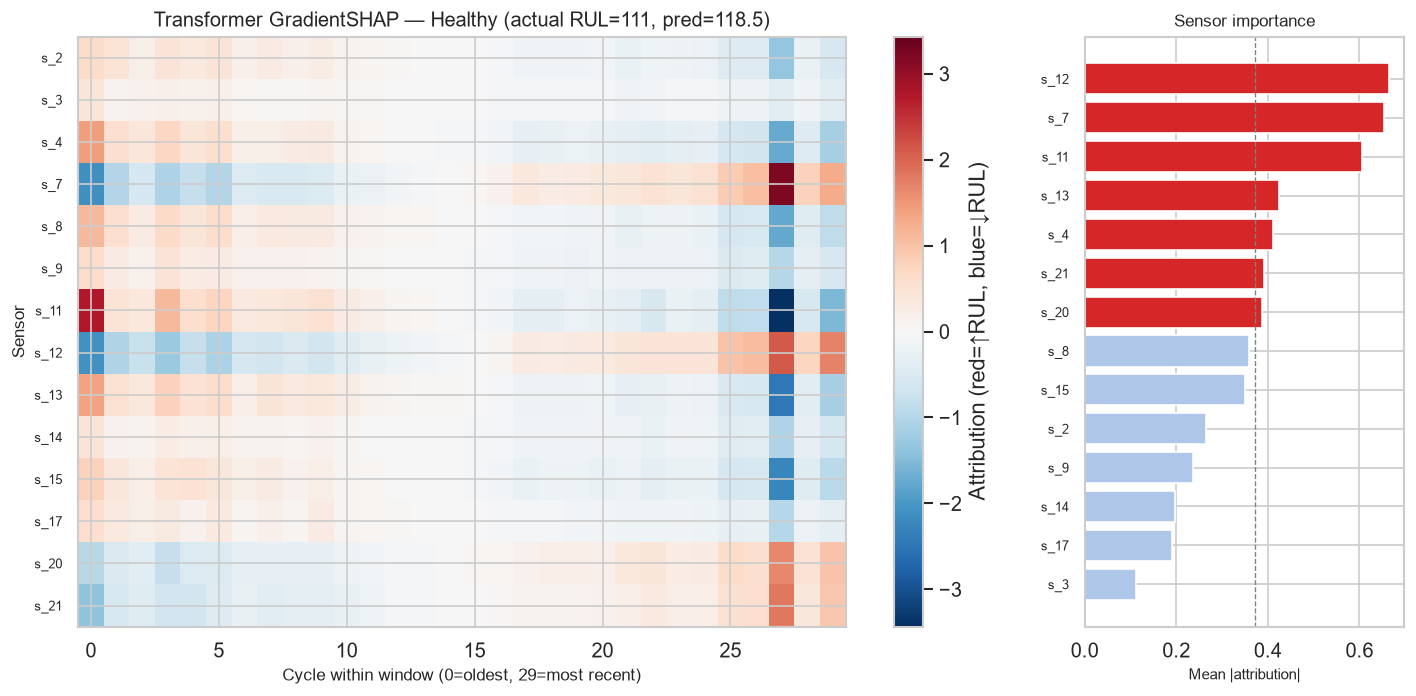

Healthy: top 3 sensors
  1. s_12    mean|attr|=0.6650
  2. s_7     mean|attr|=0.6531
  3. s_11    mean|attr|=0.6058

Saved → C:\Users\rumma\OneDrive\Desktop\Dissertation\xpdm_starter\outputs\figures\shap_transformer_FD001_mid_life.png


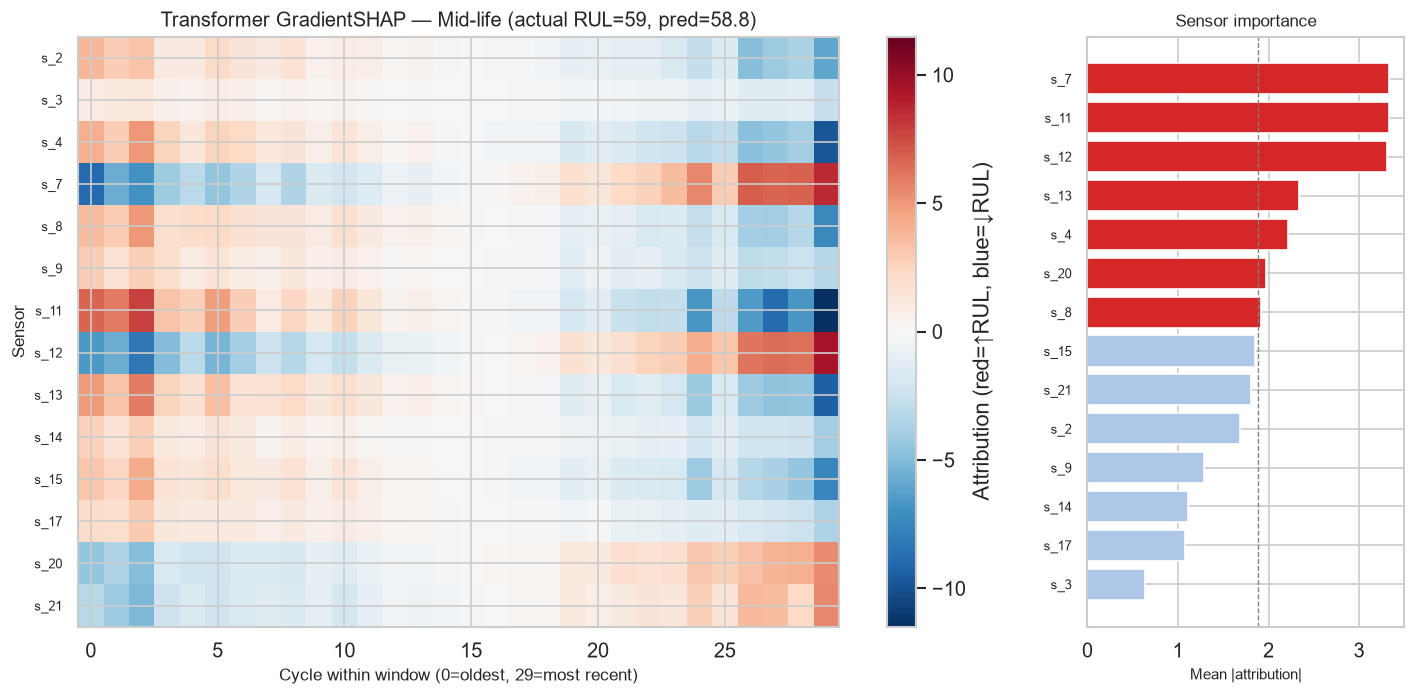

Mid-life: top 3 sensors
  1. s_7     mean|attr|=3.3346
  2. s_11    mean|attr|=3.3311
  3. s_12    mean|attr|=3.3137

Saved → C:\Users\rumma\OneDrive\Desktop\Dissertation\xpdm_starter\outputs\figures\shap_transformer_FD001_near_failure.png


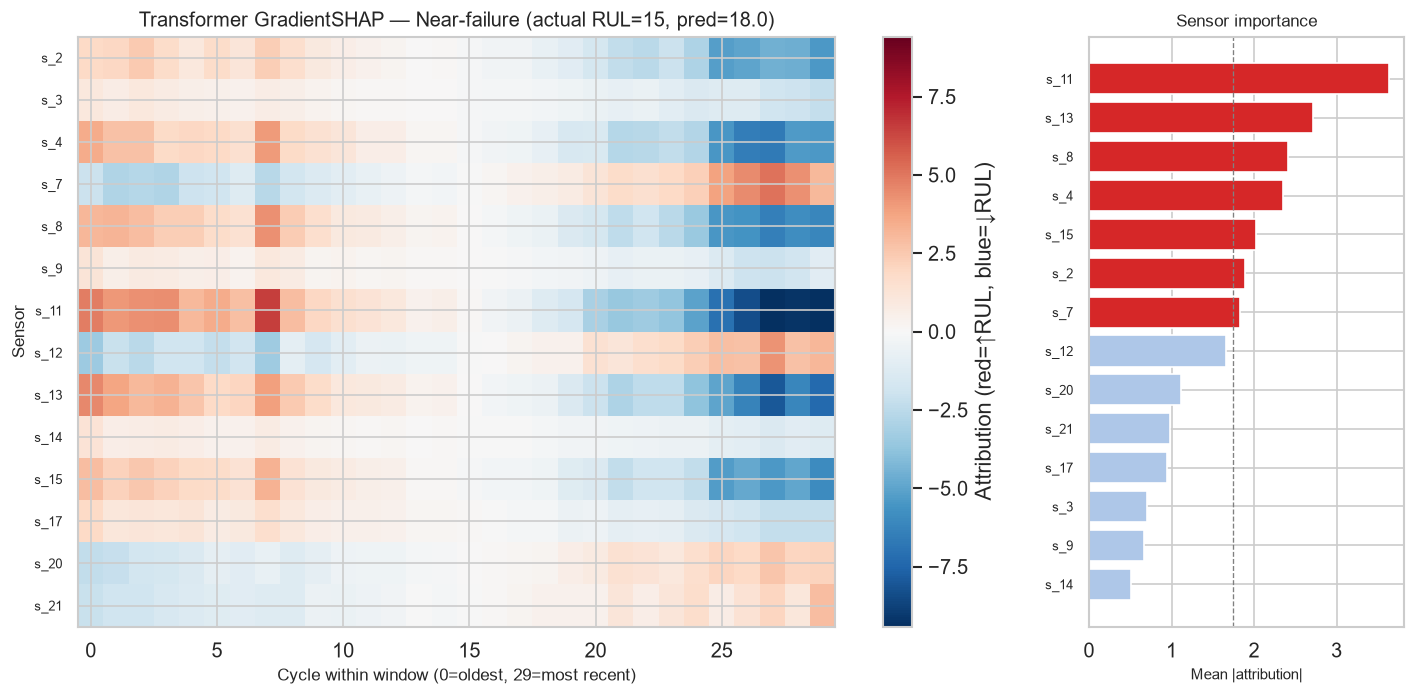

Near-failure: top 3 sensors
  1. s_11    mean|attr|=3.6407
  2. s_13    mean|attr|=2.7086
  3. s_8     mean|attr|=2.4090



In [8]:
trans_explainer = GradientSHAPExplainer(trans_model, DEVICE, n_samples=50)

for label, eid, rul in zip(engine_labels, engine_ids, actual_ruls):
    window = torch.tensor(X_test[eid:eid+1], dtype=torch.float32)

    with torch.no_grad():
        pred = trans_model(window.to(DEVICE)).item()

    attr = trans_explainer.attribute(window)

    trans_explainer.plot(
        attr,
        sensor_names = SENSORS,
        title  = f'Transformer GradientSHAP — {label} (actual RUL={rul:.0f}, pred={pred:.1f})',
        save_path = OUT_FIGURES / f'shap_transformer_{SUBSET}_{label.lower().replace("-","_")}.png',
    )

    importance = np.abs(attr).mean(axis=0)
    top3 = np.argsort(importance)[::-1][:3]
    print(f'{label}: top 3 sensors')
    for rank, idx in enumerate(top3, 1):
        print(f'  {rank}. {SENSORS[idx]:<6}  mean|attr|={importance[idx]:.4f}')
    print()

## 6 · Cross-model sensor importance comparison — near-failure engine

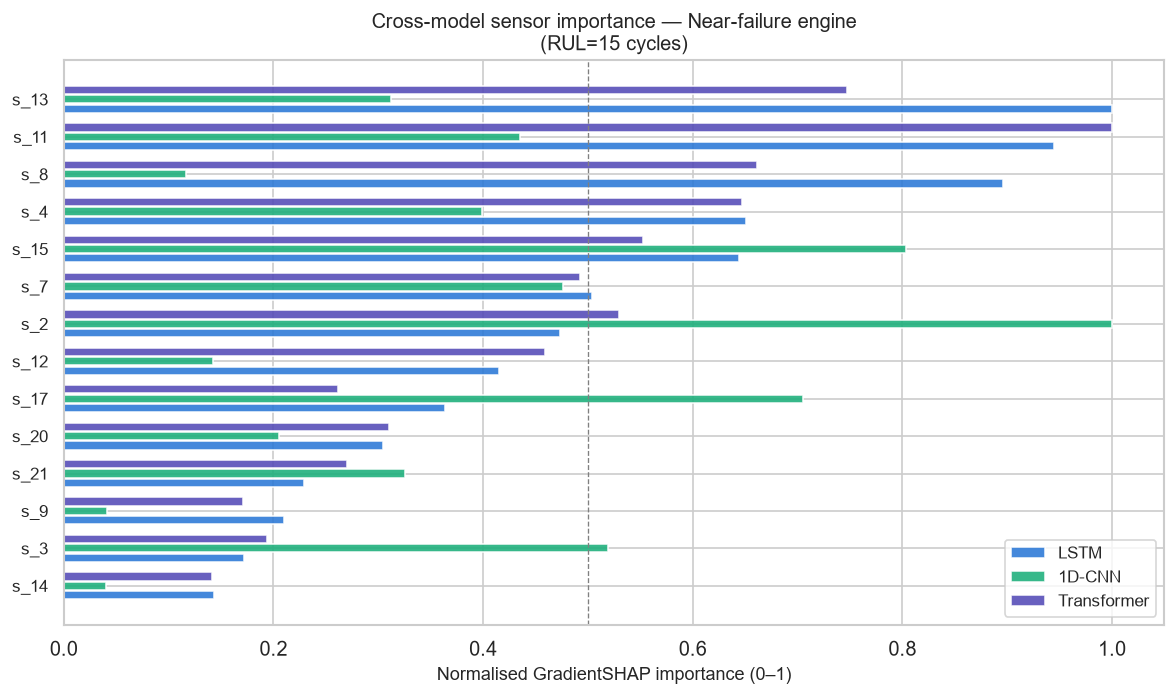


Sensor importance rankings (1=most important):
Sensor     LSTM    CNN    Trans
--------------------------------
s_2           7      1        6
s_3          13      4       12
s_4           4      7        4
s_7           6      5        7
s_8           3     12        3
s_9          12     13       13
s_11          2      6        1
s_12          8     11        8
s_13          1      9        2
s_14         14     14       14
s_15          5      2        5
s_17          9      3       11
s_20         10     10        9
s_21         11      8       10


In [9]:
# Focus on the near-failure engine — most interesting for maintenance
eid_fail = engine_ids[2]   # near-failure index
window   = torch.tensor(X_test[eid_fail:eid_fail+1], dtype=torch.float32)

# Compute attributions from all 3 models
attr_lstm  = lstm_explainer.attribute(window)
attr_cnn   = cnn_explainer.attribute(window)
attr_trans = trans_explainer.attribute(window)

# Sensor importance per model (mean |attribution| across 30 cycles)
imp_lstm  = np.abs(attr_lstm).mean(axis=0)
imp_cnn   = np.abs(attr_cnn).mean(axis=0)
imp_trans = np.abs(attr_trans).mean(axis=0)

# Normalise to [0,1] for fair comparison
imp_lstm  = imp_lstm  / imp_lstm.max()
imp_cnn   = imp_cnn   / imp_cnn.max()
imp_trans = imp_trans / imp_trans.max()

# Sort by LSTM importance
sort_idx = np.argsort(imp_lstm)
y = np.arange(len(SENSORS))

fig, ax = plt.subplots(figsize=(10, 6))
ax.barh(y - 0.25, imp_lstm[sort_idx],  0.22, label='LSTM',        color='#2a78d6', alpha=0.88)
ax.barh(y,        imp_cnn[sort_idx],   0.22, label='1D-CNN',       color='#1baf7a', alpha=0.88)
ax.barh(y + 0.25, imp_trans[sort_idx], 0.22, label='Transformer',  color='#534AB7', alpha=0.88)

ax.set_yticks(y)
ax.set_yticklabels([SENSORS[i] for i in sort_idx], fontsize=10)
ax.set_xlabel('Normalised GradientSHAP importance (0–1)', fontsize=11)
ax.set_title(f'Cross-model sensor importance — Near-failure engine\n'
             f'(RUL={y_test[eid_fail]:.0f} cycles)', fontsize=12)
ax.legend(fontsize=10)
ax.axvline(0.5, color='grey', linestyle='--', linewidth=0.8)

plt.tight_layout()
plt.savefig(OUT_FIGURES / f'shap_cross_model_comparison_{SUBSET}.png', bbox_inches='tight')
plt.show()

print('\nSensor importance rankings (1=most important):')
print(f'{"Sensor":<8} {"LSTM":>6} {"CNN":>6} {"Trans":>8}')
print('-'*32)
for i, s in enumerate(SENSORS):
    r_lstm  = int(np.argsort(imp_lstm)[::-1].tolist().index(i)) + 1
    r_cnn   = int(np.argsort(imp_cnn)[::-1].tolist().index(i)) + 1
    r_trans = int(np.argsort(imp_trans)[::-1].tolist().index(i)) + 1
    print(f'{s:<8} {r_lstm:>6} {r_cnn:>6} {r_trans:>8}')

## 7 · Sensor attribution over time — s_11 and s_4 for near-failure engine

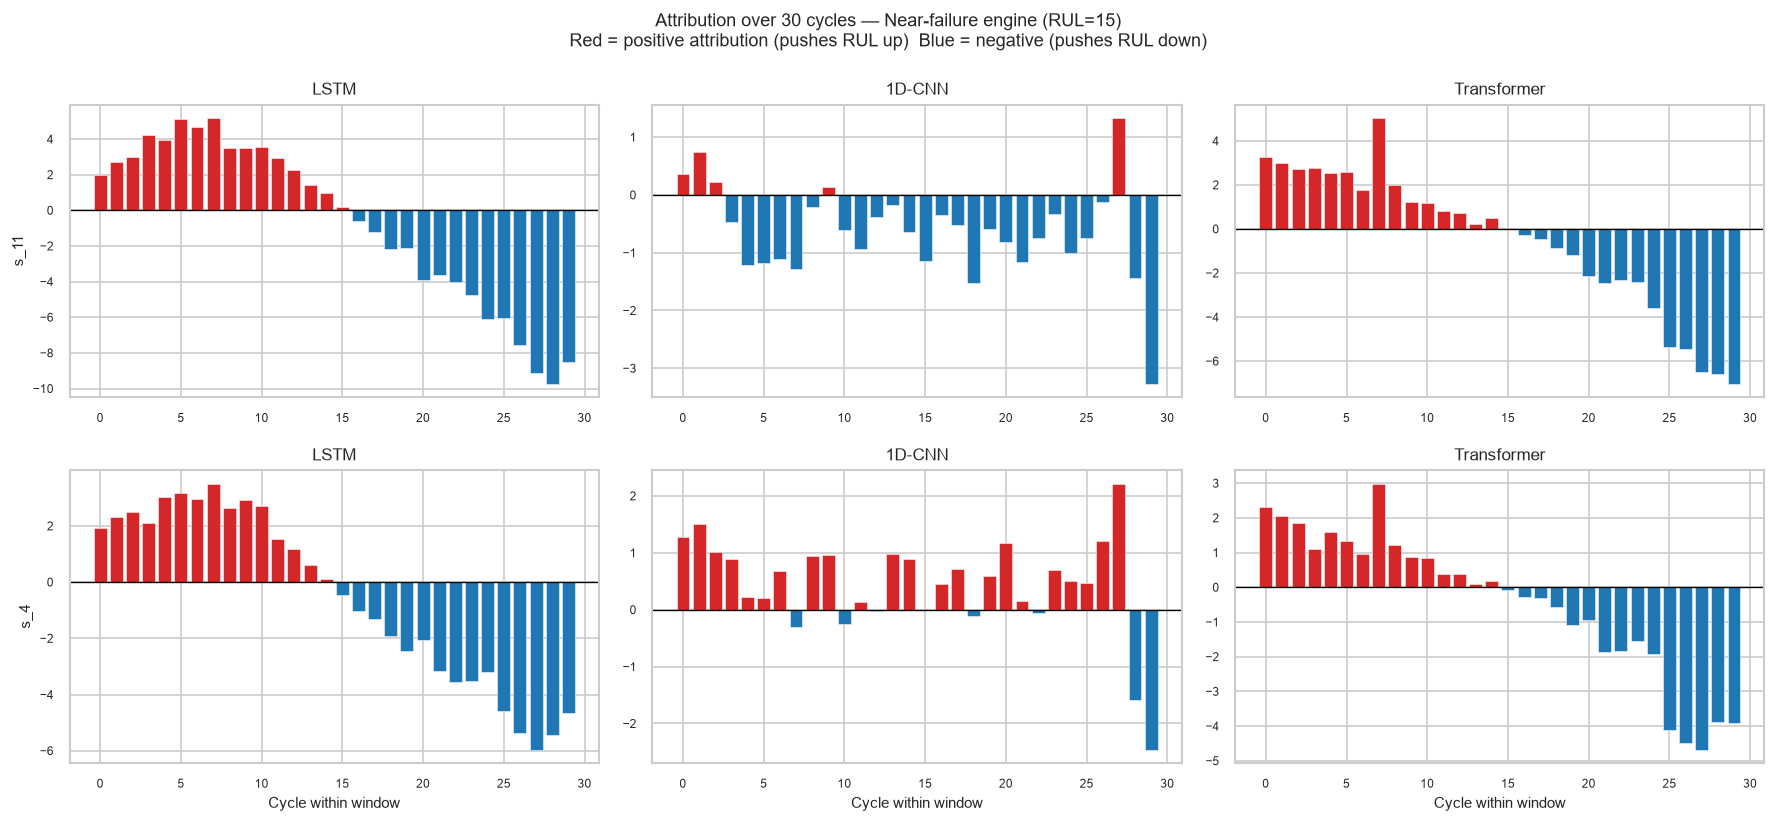

In [10]:
# Plot how attribution changes across 30 cycles for the two key sensors
fig, axes = plt.subplots(2, 3, figsize=(15, 7))

focus_sensors = [
    (SENSORS.index('s_11'), 's_11 (HPC pressure — expected to fall near failure)'),
    (SENSORS.index('s_4'),  's_4  (exhaust temp — expected to rise near failure)'),
]

model_attrs = [
    (attr_lstm,  'LSTM',        '#2a78d6'),
    (attr_cnn,   '1D-CNN',      '#1baf7a'),
    (attr_trans, 'Transformer', '#534AB7'),
]

for row, (s_idx, s_label) in enumerate(focus_sensors):
    for col, (attr, model_name, color) in enumerate(model_attrs):
        ax = axes[row][col]
        vals = attr[:, s_idx]   # (30,) — attribution over 30 cycles
        bar_colors = ['#d62728' if v > 0 else '#1f77b4' for v in vals]
        ax.bar(range(30), vals, color=bar_colors, edgecolor='white', linewidth=0.3)
        ax.axhline(0, color='black', linewidth=0.8)
        ax.set_title(f'{model_name}', fontsize=10)
        if col == 0:
            ax.set_ylabel(s_label.split('(')[0].strip(), fontsize=9)
        if row == 1:
            ax.set_xlabel('Cycle within window', fontsize=9)
        ax.tick_params(labelsize=7)

fig.suptitle(f'Attribution over 30 cycles — Near-failure engine (RUL={y_test[eid_fail]:.0f})\n'
             'Red = positive attribution (pushes RUL up)  Blue = negative (pushes RUL down)',
             fontsize=11)
plt.tight_layout()
plt.savefig(OUT_FIGURES / f'shap_over_time_{SUBSET}.png', bbox_inches='tight')
plt.show()

## 8 · Validate against EDA findings

In [11]:
print('='*60)
print('VALIDATION: do SHAP attributions agree with EDA findings?')
print('='*60)
print('\nEDA found these sensors most correlated with RUL:')
print('  s_11 |r|=0.696  s_4 |r|=0.679  s_12 |r|=0.672')
print('  s_7  |r|=0.657  s_15|r|=0.643  s_21 |r|=0.636')
print()

expected_top = {'s_11', 's_4', 's_12', 's_7', 's_15', 's_21'}

for attr, model_name in [(attr_lstm,'LSTM'),(attr_cnn,'CNN'),(attr_trans,'Transformer')]:
    imp    = np.abs(attr).mean(axis=0)
    top6   = set(SENSORS[i] for i in np.argsort(imp)[::-1][:6])
    overlap = top6 & expected_top
    print(f'{model_name}:')
    print(f'  Top 6 by SHAP : {sorted(top6)}')
    print(f'  Overlap w/ EDA: {sorted(overlap)} ({len(overlap)}/6 match)')
    print()

print('='*60)
print('High overlap confirms SHAP attributions are physically meaningful.')
print('Low overlap for CNN may explain its weaker RMSE performance.')

VALIDATION: do SHAP attributions agree with EDA findings?

EDA found these sensors most correlated with RUL:
  s_11 |r|=0.696  s_4 |r|=0.679  s_12 |r|=0.672
  s_7  |r|=0.657  s_15|r|=0.643  s_21 |r|=0.636

LSTM:
  Top 6 by SHAP : ['s_11', 's_13', 's_15', 's_4', 's_7', 's_8']
  Overlap w/ EDA: ['s_11', 's_15', 's_4', 's_7'] (4/6 match)

CNN:
  Top 6 by SHAP : ['s_11', 's_15', 's_17', 's_2', 's_3', 's_7']
  Overlap w/ EDA: ['s_11', 's_15', 's_7'] (3/6 match)

Transformer:
  Top 6 by SHAP : ['s_11', 's_13', 's_15', 's_2', 's_4', 's_8']
  Overlap w/ EDA: ['s_11', 's_15', 's_4'] (3/6 match)

High overlap confirms SHAP attributions are physically meaningful.
Low overlap for CNN may explain its weaker RMSE performance.
